In [1]:
import os
import pandas as pd
import joblib
import shap
import matplotlib.pyplot as plt

d:\Explainable-AI-CDSS\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
BASE_DIR = os.path.abspath(os.path.join(os.getcwd(), ".."))

PROCESSED_DIR = os.path.join(BASE_DIR, "datasets", "processed", "ckd")
MODEL_DIR = os.path.join(BASE_DIR, "models", "ckd")

X_train = pd.read_csv(os.path.join(PROCESSED_DIR, "x_train.csv"))
X_test = pd.read_csv(os.path.join(PROCESSED_DIR, "x_test.csv"))

ckd_model = joblib.load(
    os.path.join(MODEL_DIR, "best_model.pkl")
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("CKD model:", type(ckd_model).__name__)

X_train: (319, 24)
X_test: (80, 24)
CKD model: RandomForestClassifier


In [3]:
# Create SHAP Tree Explainer

explainer = shap.TreeExplainer(ckd_model)

shap_values = explainer.shap_values(X_test)

print("SHAP values generated successfully!")
print("SHAP output type:", type(shap_values))

SHAP values generated successfully!
SHAP output type: <class 'numpy.ndarray'>


In [4]:
print("X_test shape:", X_test.shape)

if isinstance(shap_values, list):
    print("Number of classes:", len(shap_values))
    print("Positive class SHAP shape:", shap_values[1].shape)
else:
    print("SHAP shape:", shap_values.shape)

X_test shape: (80, 24)
SHAP shape: (80, 24, 2)


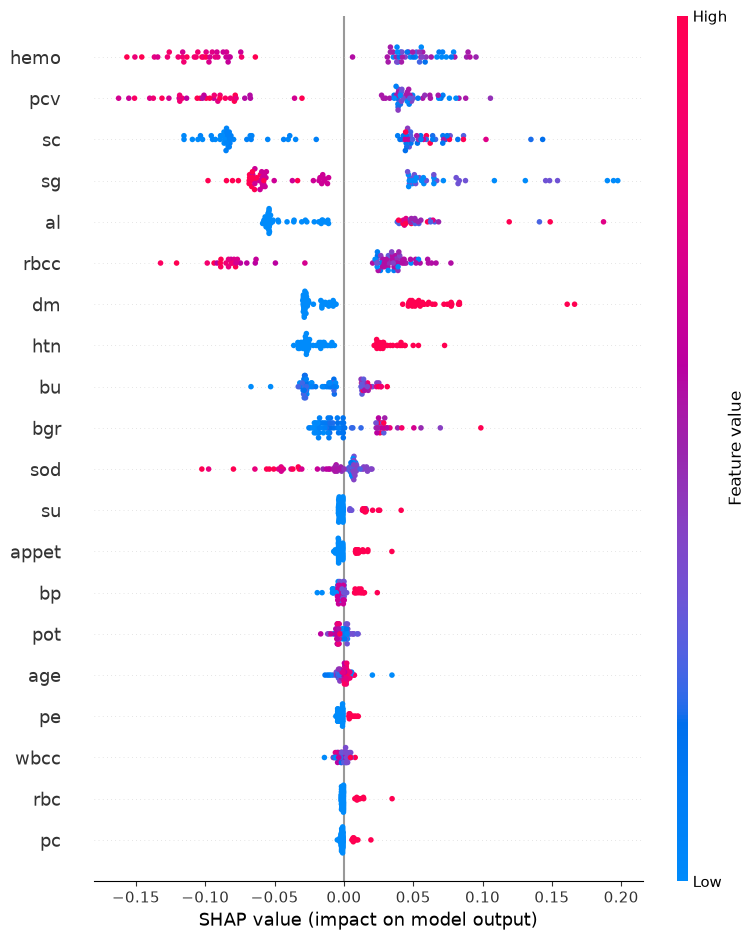

In [6]:
# CKD SHAP Summary Plot

if isinstance(shap_values, list):
    positive_shap = shap_values[1]
else:
    positive_shap = shap_values[:, :, 1] if shap_values.ndim == 3 else shap_values

shap.summary_plot(
    positive_shap,
    X_test,
    feature_names=X_test.columns
)

In [7]:
# Global feature importance using mean absolute SHAP values

if isinstance(shap_values, list):
    positive_shap = shap_values[1]
else:
    positive_shap = (
        shap_values[:, :, 1]
        if shap_values.ndim == 3
        else shap_values
    )

feature_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean Absolute SHAP": abs(positive_shap).mean(axis=0)
})

feature_importance = feature_importance.sort_values(
    "Mean Absolute SHAP",
    ascending=False
)

feature_importance.head(10)

,Feature,Mean Absolute SHAP
14,hemo,0.075279
15,pcv,0.071505
11,sc,0.070780
2,sg,0.065264
3,al,0.051110
17,rbcc,0.050822
19,dm,0.041473
18,htn,0.026929
10,bu,0.020724
9,bgr,0.019186


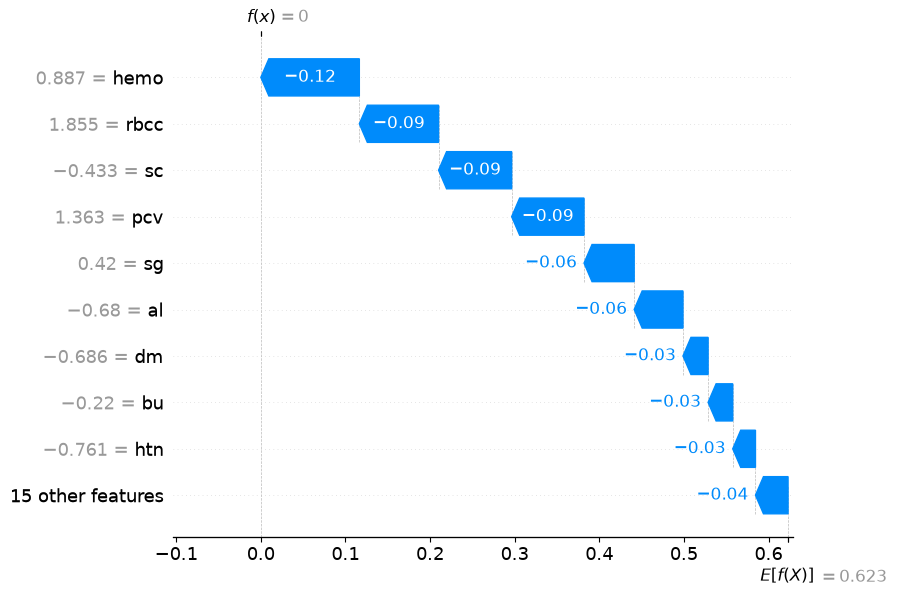

In [9]:
# Individual CKD SHAP explanation

patient_index = 0

patient_shap = positive_shap[patient_index]
patient_data = X_test.iloc[patient_index]

# Get a single base value for CKD class
if isinstance(explainer.expected_value, (list, tuple)):
    base_value = float(explainer.expected_value[1])
else:
    base_array = explainer.expected_value

    if hasattr(base_array, "ndim") and base_array.ndim > 0:
        base_value = float(base_array[1])
    else:
        base_value = float(base_array)

shap_explanation = shap.Explanation(
    values=patient_shap,
    base_values=base_value,
    data=patient_data.values,
    feature_names=X_test.columns
)

shap.plots.waterfall(shap_explanation)

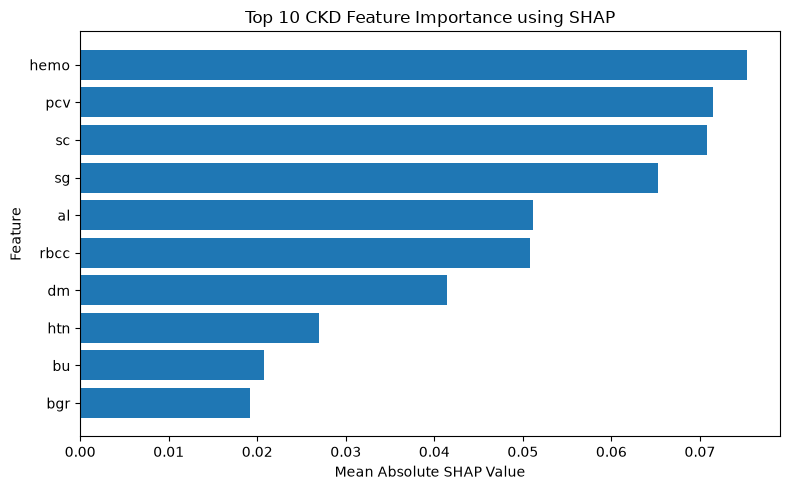

In [10]:
# CKD Global SHAP Feature Importance

top_features = feature_importance.head(10).sort_values(
    "Mean Absolute SHAP"
)

plt.figure(figsize=(8, 5))

plt.barh(
    top_features["Feature"],
    top_features["Mean Absolute SHAP"]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.title("Top 10 CKD Feature Importance using SHAP")

plt.tight_layout()
plt.show()

In [11]:
# Save CKD SHAP feature importance

SHAP_DIR = os.path.join(
    BASE_DIR,
    "datasets",
    "processed",
    "ckd"
)

feature_importance.to_csv(
    os.path.join(SHAP_DIR, "shap_feature_importance.csv"),
    index=False
)

print("CKD SHAP feature importance saved successfully!")

CKD SHAP feature importance saved successfully!


In [12]:
# Verify saved SHAP feature importance

shap_file = os.path.join(
    BASE_DIR,
    "datasets",
    "processed",
    "ckd",
    "shap_feature_importance.csv"
)

if os.path.exists(shap_file):
    print("✓ CKD SHAP feature importance saved successfully")
    print("\nTop 10 CKD features:")
    print(feature_importance.head(10))
else:
    print("✗ SHAP feature importance file not found")

✓ CKD SHAP feature importance saved successfully

Top 10 CKD features:
   Feature  Mean Absolute SHAP
14    hemo            0.075279
15     pcv            0.071505
11      sc            0.070780
2       sg            0.065264
3       al            0.051110
17    rbcc            0.050822
19      dm            0.041473
18     htn            0.026929
10      bu            0.020724
9      bgr            0.019186
